# Laboratorio · Predecir propinas con Python
**Regresión lineal · Ejercicio individual**

**Dataset:** `tips.csv`, 244 cuentas de restaurante. [Ver dataset en Kaggle](https://www.kaggle.com/datasets/sakshisatre/tips-dataset).

**Problema:** estimar `tip` (propina en USD) a partir de `total_bill` (cuenta en USD) y después comprobar si `size` (número de personas) aporta valor.

**Instrucciones:** ejecutar las actividades en orden, completar las celdas de código y responder las preguntas con resultados propios. El archivo CSV debe estar junto al notebook.

## 01 · Explorar el CSV
**Objetivo.** Cargar `tips.csv` y mostrar **cinco filas**, dimensiones, valores faltantes y resumen numérico.

*Pista:* `pd.read_csv()`, `.head()`, `.shape`, `.isna().sum()`, `.describe()`.

**Resultado esperado:** Una tabla y el resumen inicial.

In [5]:
import pandas as pd

# Cargar el dataset
df = pd.read_csv("tips.csv")

print("Primeras 5 filas")
print(df.head())

print("Dimensiones")
print(df.shape)

print("Valores faltantes por columna")
print(df.isna().sum())

print("Resumen numérico")
print(df.describe())



Primeras 5 filas
   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4
Dimensiones
(244, 7)
Valores faltantes por columna
total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64
Resumen numérico
       total_bill         tip        size
count  244.000000  244.000000  244.000000
mean    19.785943    2.998279    2.569672
std      8.902412    1.383638    0.951100
min      3.070000    1.000000    1.000000
25%     13.347500    2.000000    2.000000
50%     17.795000    2.900000    2.000000
75%     24.127500    3.562500    3.000000
max     50.810000   10.000000    6.000000


## 02 · Separar entradas y objetivo
**Objetivo.** Crear `X` con la cuenta total (`total_bill`) y `y` con la propina real (`tip`). Mostrar sus primeras filas y dimensiones.

*Pista:* `datos[["total_bill"]]` devuelve una tabla; `datos["tip"]` devuelve la serie objetivo.

**Resultado esperado:** Entradas y objetivos claramente identificados.

In [12]:

X = df[["total_bill"]]  
Y = df["tip"]           

print("Primeras filas de X")
print(X.head())
print("Dimensiones de X:", X.shape)

print("Primeras filas de y")
print(y.head())
print("\nDimensiones de y:", Y.shape)

Primeras filas de X
   total_bill
0       16.99
1       10.34
2       21.01
3       23.68
4       24.59
Dimensiones de X: (244, 1)
Primeras filas de y
0    1.01
1    1.66
2    3.50
3    3.31
4    3.61
Name: tip, dtype: float64

Dimensiones de y: (244,)


## 03 · Crear entrenamiento y prueba
**Objetivo.** Reservar el 25 % de los registros para evaluar, usando `random_state=42`. Mostrar cuántas filas quedan en cada conjunto.

*Pista:* `train_test_split()` del módulo `sklearn.model_selection`.

**Resultado esperado:** Tamaños de `X_train`, `X_test`, `y_train`, `y_test`.

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.25,random_state=42)

# Cantidad de filas y dimensiones en cada conjunto
print("Tamaño de X_train:", X_train.shape)
print("Tamaño de X_test:", X_test.shape)
print("Tamaño de y_train:", Y_train.shape)
print("Tamaño de y_test:", Y_test.shape)

# Conteo directo de filas
print(f"\nFilas para entrenamiento: {len(X_train)}")
print(f"Filas para prueba: {len(X_test)}")

Tamaño de X_train: (183, 1)
Tamaño de X_test: (61, 1)
Tamaño de y_train: (183,)
Tamaño de y_test: (61,)

Filas para entrenamiento: 183
Filas para prueba: 61


## 04 · Entrenar y predecir
**Objetivo.** Crear una regresión, ajustarla con entrenamiento y predecir las propinas del conjunto de prueba. Mostrar cinco predicciones.

*Pista:* `LinearRegression()`, `.fit()`, `.predict()`.

**Resultado esperado:** Cinco importes estimados.

In [29]:
from sklearn.linear_model import LinearRegression

modelo = LinearRegression()

modelo.fit(X_train, Y_train)

Y_pred = modelo.predict(X_test)

print("Primeras 5 predicciones")
print(Y_pred[:5])

Primeras 5 predicciones
[3.03019394 1.82116362 3.54772457 3.69434001 2.28398699]


## 05 · Evaluar los errores
**Objetivo.** Calcular **MAE, MSE, RMSE y R²** sobre los datos de prueba e imprimir sus valores.

*Pista:* `sklearn.metrics`; para RMSE se puede usar `mse ** 0.5`.

**Resultado esperado:** Cuatro indicadores numéricos.

In [37]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(Y_test, Y_pred)
mse = mean_squared_error(Y_test, Y_pred)
rmse = mse ** 0.5  
r2 = r2_score(Y_test, Y_pred)


print("Métricas de evaluación en prueba")
print(f"MAE  (Error Absoluto Medio):            {mae:.4f}")
print(f"MSE  (Error Cuadrático Medio):          {mse:.4f}")
print(f"RMSE (Raíz del Error Cuadrático Medio): {rmse:.4f}")
print(f"R²   (Coeficiente de Determinación):    {r2:.4f}")

Métricas de evaluación en prueba
MAE  (Error Absoluto Medio):            0.6522
MSE  (Error Cuadrático Medio):          0.7449
RMSE (Raíz del Error Cuadrático Medio): 0.8631
R²   (Coeficiente de Determinación):    0.4401


## 06 · Graficar datos y predicción
**Objetivo.** Construir una tabla de cinco valores reales y predichos. Dibujar los puntos reales y la recta del modelo, con nombres en los ejes y leyenda.

*Pista:* `pd.DataFrame()`, `plt.scatter()`, `plt.plot()`; ordenar X solo para dibujar la línea.

**Resultado esperado:** Tabla comparativa y gráfico.

Comparativa de 5 valores
   Real   Prediccion
0   3.18    3.030194
1   2.00    1.821164
2   2.00    3.547725
3   5.16    3.694340
4   2.00    2.283987


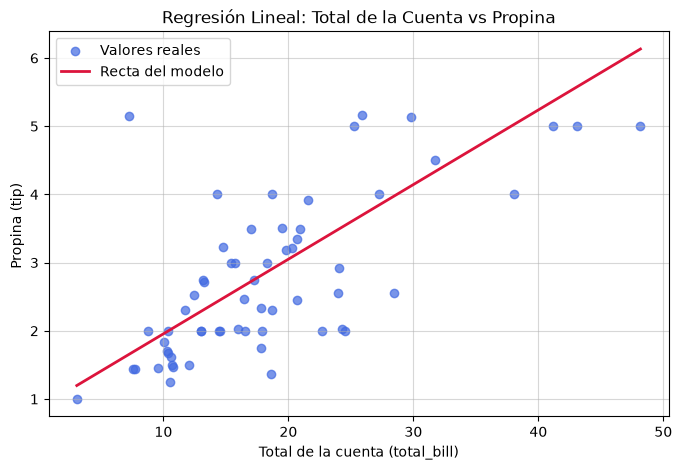

In [39]:
import matplotlib.pyplot as plt
import pandas as pd

#tabla con cinco valores reales y predichos
comparativa = pd.DataFrame({
    "Real ": Y_test.values[:5],
    "Prediccion": Y_pred[:5]
})

print("Comparativa de 5 valores")
print(comparativa)

X_test_ordenado = X_test.sort_values(by="total_bill")
Y_pred_linea = modelo.predict(X_test_ordenado)

#Dibujar el gráfico de dispersion y la recta de regresion
plt.figure(figsize=(8, 5))
plt.scatter(X_test, Y_test, color="royalblue", alpha=0.7, label="Valores reales")
plt.plot(X_test_ordenado, Y_pred_linea, color="crimson", linewidth=2, label="Recta del modelo")

# Etiquetas, titulo y leyenda
plt.title("Regresión Lineal: Total de la Cuenta vs Propina")
plt.xlabel("Total de la cuenta (total_bill)")
plt.ylabel("Propina (tip) ")
plt.legend()
plt.grid(True, linestyle="-", alpha=0.5)
plt.show()

## 07 · Inspeccionar residuos
**Objetivo.** Calcular `real − predicho`; graficar los residuos contra las predicciones, con una línea horizontal en cero.

*Pista:* `.to_numpy()`, `plt.scatter()`, `plt.axhline(0)`.

**Resultado esperado:** Gráfico de residuos.

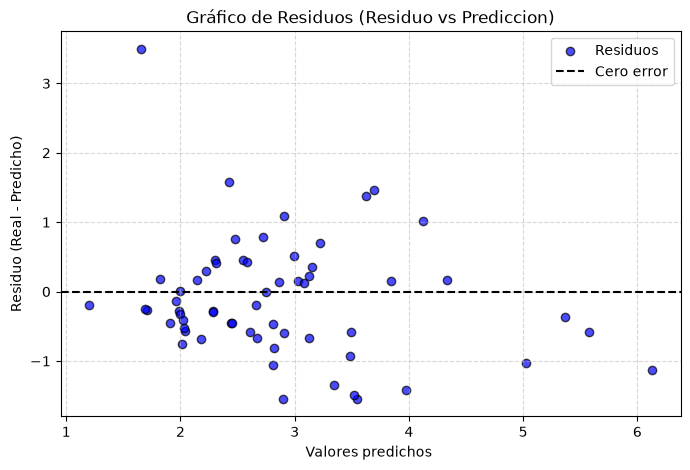

In [42]:
import matplotlib.pyplot as plt

# Calcular los residuos: 
residuos = Y_test.to_numpy() - Y_pred

# Graficar
plt.figure(figsize=(8, 5))
plt.scatter(Y_pred, residuos, color="blue", alpha=0.7, edgecolors="k", label="Residuos")

# Dibujar la línea horizontal de referencia en cero
plt.axhline(0, color="black", linestyle="--", linewidth=1.5, label="Cero error")

# Etiquetas, titulo y leyenda
plt.title("Gráfico de Residuos (Residuo vs Prediccion)")
plt.xlabel("Valores predichos ")
plt.ylabel("Residuo (Real - Predicho)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

## 08 · Comparar una y dos entradas
**Objetivo.** Entrenar un segundo modelo usando `total_bill` y `size` juntos. Comparar **MAE, RMSE y R²** con el modelo inicial.

*Pista:* Definir `X2` con dos columnas y repetir la partición con el mismo `random_state`.

**Resultado esperado:** Comparación numérica de ambos modelos.

In [43]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

X2 = df[["total_bill", "size"]]

X2_train, X2_test, Y2_train, Y2_test = train_test_split(X2, Y, test_size=0.25, random_state=42)

modelo_2 = LinearRegression()
modelo_2.fit(X2_train, Y2_train)
Y2_pred = modelo_2.predict(X2_test)

mae_2 = mean_absolute_error(Y2_test, Y2_pred)
rmse_2 = mean_squared_error(Y2_test, Y2_pred) ** 0.5
r2_2 = r2_score(Y2_test, Y2_pred)

tabla_comparativa = pd.DataFrame(
    {
        "Métrica": ["MAE", "RMSE", "R²"],
        "Modelo 1 (total_bill)": [mae, rmse, r2],
        "Modelo 2 (total_bill + size)": [mae_2, rmse_2, r2_2],
    }
)

print("Comparacion")
print(tabla_comparativa.to_string(index=False))

Comparacion
Métrica  Modelo 1 (total_bill)  Modelo 2 (total_bill + size)
    MAE               0.652210                      0.673396
   RMSE               0.863052                      0.879949
     R²               0.440135                      0.417998


## Preguntas de desarrollo
Responder con los resultados obtenidos y, cuando corresponda, hacer referencia a los gráficos.

1. ¿Qué información contiene `X` y cuál es el objetivo `y`? ¿Qué cambia en la entrada cuando se agrega `size`?
2. ¿Cómo interpretar el MAE del primer modelo en **dólares de propina**? Dar un ejemplo de su significado.
3. ¿Qué diferencia existe entre MAE y RMSE? ¿Qué sugiere que RMSE sea mayor?
4. ¿Qué representa el R² obtenido? Explicar por qué **no** es un porcentaje de predicciones correctas.
5. ¿Qué se observa en el gráfico de residuos? ¿Hay valores especialmente alejados de cero?
6. ¿El modelo con dos entradas mejora los resultados en test? Justificar con MAE, RMSE y R² y proponer una explicación posible.

### Respuestas

**1.**: X Contiene la variable predictoria o el total de la cuenta, por otro lado y contiene la variable a predecir, la propina entregada por el cliente. Los valores de entrada pasan a tener 2 columnas

**2.**: El Error Absoluto Medio mide el promedio de las desviaciones absolutas entre la propina calculada por el modelo y la propina real dejada y es de 0.73

**3.** :El MAE promedia linealmente todas las distancias absolutas de error, ponderándolas por igual. El RMSE eleva los errores al cuadrado antes de promediarlos y aplicarles raíz cuadrada, lo cual penaliza con mucha más fuerza los errores individuales grandes.

**4.**: Representa la proporcion de la varianza total de las propinas que es explicada por la recta de regresion a partir de la cuenta total. Es decir, cerca del 40 % de cómo varía la propina depende linealmente del valor consumido. No es un porcentaje de prediciones ya que la propina es un valor continuo no una clasificacion binaria.

**5.** En el grafico de residuos contra valores predichos se aprecia una ligera heterocedasticidad: a medida que la predicción crece, la dispersión vertical de los puntos aumenta en forma de embudo. Sí hay valores alejados, se observan puntos claramente atípicos con residuos positivos elevados, correspondientes a clientes generosos.

**6.** El cambio sobre el conjunto de test es pequeño, apenas experimenta una variación muy leve y tanto MAE como RMSE muestran reducciones mínimas. El total de la cuenta ya captura de forma indirecta la mayor parte de la información que aporta el número de comensales, haciendo que size proporcione poca información predictiva.